In [1]:
import pandas as pd
from tqdm import tqdm
import os
import ast
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

import loess
from loess import loess_1d

In [2]:
prefix='all_six'
# Non-y1000 seqs
all_combined_no_y1000 = pd.read_csv(f'../predictions/combined_preds/non_cl_seqs_{prefix}_combined_filtered.csv', 
                              index_col=0,
                              converters={'combined_preds' : ast.literal_eval,
                                          'adhunter_preds' : ast.literal_eval,
                                          'adhunter_ensemble_preds' : ast.literal_eval,
                                          'tada_preds' : ast.literal_eval,
                                          'adpred_preds' : ast.literal_eval,
                                          'paddle_preds' : ast.literal_eval,
                                          'adhunter_centers' : ast.literal_eval,
                                          'adhunter_ensemble_centers' : ast.literal_eval,
                                          'tada_centers' : ast.literal_eval,
                                          'paddle_centers' : ast.literal_eval
                                         })

# y1000 seqs
all_combined_y1000 = pd.read_csv(f'../predictions/combined_preds/y1000_filtered_{prefix}_combined.csv', 
                              index_col=0,
                              converters={'combined_preds' : ast.literal_eval,
                                          'adhunter_preds' : ast.literal_eval,
                                          'adhunter_ensemble_preds' : ast.literal_eval,
                                          'tada_preds' : ast.literal_eval,
                                          'adpred_preds' : ast.literal_eval,
                                          'paddle_preds' : ast.literal_eval,
                                          'adhunter_centers' : ast.literal_eval,
                                          'adhunter_ensemble_centers' : ast.literal_eval,
                                          'tada_centers' : ast.literal_eval,
                                          'paddle_centers' : ast.literal_eval
                                         })


In [3]:
# These are representative cluster sequences for the full length TFs
# in the test set of Sanborn that we use to test

seqs_to_remove = ['g000011.m1_saccharomyces_paradoxus.final',
'g001558.m1_saccharomyces_arboricola.final',
'g005241.m1_saccharomyces_mikatae.final',
'g003121.m1_saccharomyces_eubayanus.final',
'g005100.m1_saccharomyces_paradoxus.final',
'g000689.m1_saccharomyces_cerevisiae.final',
'g001197.m1_saccharomyces_arboricola.final',
'g000300.m1_saccharomyces_uvarum.final',
'g000966.m1_saccharomyces_eubayanus.final',
'g002878.m1_saccharomyces_kudriavzevii.final',
'g002484.m1_saccharomyces_mikatae.final',
'g002667.m1_saccharomyces_cerevisiae.final',
'g004608.m1_saccharomyces_paradoxus.final',
'g001455.m1_saccharomyces_kudriavzevii.final',
'g003829.m1_saccharomyces_kudriavzevii.final',
'P07249',
'g002480.m1_saccharomyces_uvarum.final']

all_combined_y1000 = all_combined_y1000[[n not in seqs_to_remove for n in all_combined_y1000['name']]]
# Concatenate both!
all_combined = pd.concat([all_combined_no_y1000, all_combined_y1000])

# Smoothing predictions

In [4]:
# Do Loess smoothening: From Max's Step2_AddSeqFeaturestoDataFrame_Oct_2024.ipynb
def smooth_activity(pred_ls, centers_ls, length): 
    X = centers_ls
    Y = pred_ls
    
    #From Max: Nick you might want degree=1, which is first order polynomial spline fitting
    #From Max: npoints means use the 20 closest tiles in either direction, but weight them by distance. 
    #From Max: I messed around with this by hand. 
    _, y_smooth, _ = loess.loess_1d.loess_1d(X, Y, xnew=range(length), degree=2, 
                        npoints=20, rotate=False, sigy=None)
    
    # correct the first 20 and last 20 entries in the output
    # the 2nd order polynomial can go negative or shoot to big numbers.
    mod_y_smooth = y_smooth
    start = max(y_smooth[20],0)
    mod_y_smooth[0:20] = start
    end = max(y_smooth[-20],0)
    mod_y_smooth[-20:] = end

    # This part made it so that the activity was not more than the activity in S. cerevisiae
    # I'm not going to impose that
    # modyout2 = np.clip(modyout,a_min=minActivity,a_max=maxActivity)

    return mod_y_smooth

In [5]:
all_combined = all_combined.reset_index(drop=True)

In [ ]:
len(all_combined.loc[0, 'sequence'])

In [12]:
all_combined['adhunter_preds_smoothed'] = [smooth_activity(np.array(a), 
                                                            np.array(b), 
                                                            len(c)) for a, b, c, in tqdm(zip(all_combined['adhunter_preds'], 
                                                                                                all_combined['adhunter_centers'], 
                                                                                                all_combined['sequence']), total=len(all_combined))]

  0%|          | 211/230284 [00:21<6:34:05,  9.73it/s]


KeyboardInterrupt: 

In [35]:
smooth_activity(np.array(all_combined.loc[0, 'adhunter_preds']), 
                np.array(ast.literal_eval(all_combined.loc[0, 'adhunter_centers'])), 
                len(all_combined.loc[0, 'sequence']))

array([27473.04773108, 27473.04773108, 27473.04773108, 27473.04773108,
       27473.04773108, 27473.04773108, 27473.04773108, 27473.04773108,
       27473.04773108, 27473.04773108, 27473.04773108, 27473.04773108,
       27473.04773108, 27473.04773108, 27473.04773108, 27473.04773108,
       27473.04773108, 27473.04773108, 27473.04773108, 27473.04773108,
       27473.04773108, 30000.75246311, 32319.94968629, 34430.73782227,
       36291.62704714, 37918.30323689, 39339.05210496, 40454.9032005 ,
       41481.77586859, 42477.99717992, 43378.2676131 , 44062.90365265,
       44441.42641666, 44741.58650474, 44994.55441872, 45243.67689841,
       45558.31573642, 45518.99750303, 45005.103923  , 44007.58404021,
       41865.44852468, 39573.3034647 , 38268.8048196 , 37900.18107922,
       38330.29826301, 39639.38483572, 41021.22502974, 42694.4693311 ,
       44437.19326224, 45434.16101869, 45864.53725583, 45476.98709461,
       43604.38443405, 42204.63548996, 42453.92409576, 43860.96885163,
      

# ADhunterLite

In [4]:
# We want to take all the predictions for each predictor and get the distributions 
# Get PADDLE distribution

adhunterlite_scores = np.array([a for ls in tqdm(all_combined['adhunter_preds']) for a in ls])

100%|██████████| 230284/230284 [00:01<00:00, 192929.31it/s]


In [5]:
adhunterlite_min = np.quantile(adhunterlite_scores, 0.02)

In [6]:
adhunterlite_max = np.quantile(adhunterlite_scores, 0.98)

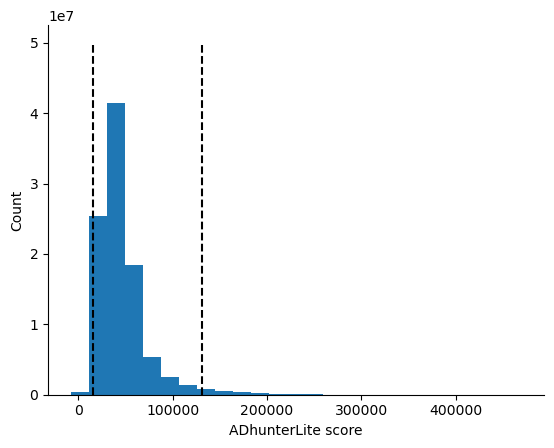

In [7]:
plt.hist(adhunterlite_scores, bins=25)
plt.vlines(15666.083, 0, 50000000, color='black', linestyle='--')
plt.vlines(131088.92, 0, 50000000, color='black', linestyle='--')
plt.xlabel("ADhunterLite score")
plt.ylabel("Count")

sns.despine()

In [8]:
def scale_ls(ls, new_min, new_max): 
    new_ls = np.array(ls)
    new_ls = (new_ls - new_min) / (new_max - new_min)
    return new_ls
        

In [9]:
(adhunterlite_scores - adhunterlite_min) / (adhunterlite_max - adhunterlite_min)

array([0.0717592 , 0.16229284, 0.16441446, ..., 0.20965372, 0.20466311,
       0.24729592], shape=(97162336,))

In [10]:
all_combined['adhunter_preds_scaled'] = all_combined['adhunter_preds'].apply(scale_ls, new_min=adhunterlite_min, new_max=adhunterlite_max) 

In [11]:
plt.hist(all_combined['adhunter_preds_scaled'].values.flatten())


KeyboardInterrupt



Error in callback <function _draw_all_if_interactive at 0x1547997b4d60> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



Error in callback <function flush_figures at 0x1542d5ececa0> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



In [ ]:
adhunterlite_scaled_scores = np.array([a for ls in tqdm(all_combined['adhunter_preds_scaled']) for a in ls])

In [ ]:
np.quantile(adhunterlite_scaled_scores, 0.02)

In [ ]:
np.quantile(adhunterlite_scaled_scores, 0.98)

In [ ]:
plt.hist(adhunterlite_scaled_scores)

# ADhunterEnsemble

In [ ]:
adhunterensemble_scores = np.array([a for ls in tqdm(all_combined['adhunter_ensemble_preds']) for a in ls])

In [ ]:
adhunterensemble_min = np.quantile(adhunterensemble_scores, 0.02)
adhunterensemble_max = np.quantile(adhunterensemble_scores, 0.98)

In [ ]:
plt.hist(adhunterensemble_scores, bins=25)
plt.vlines(adhunterensemble_min, 0, 50000000, color='black', linestyle='--')
plt.vlines(adhunterensemble_max, 0, 50000000, color='black', linestyle='--')
plt.xlabel("ADhunterEnsemble score")
plt.ylabel("Count")

sns.despine()

In [ ]:
all_combined['adhunter_ensemble_preds_scaled'] = all_combined['adhunter_ensemble_preds'].apply(scale_ls, new_min=adhunterensemble_min, new_max=adhunterensemble_max) 

In [ ]:
# Checking my work
adhunterensemble_scaled_scores = np.array([a for ls in tqdm(all_combined['adhunter_ensemble_preds_scaled']) for a in ls])
print(np.quantile(adhunterlite_scaled_scores, 0.02))
print(np.quantile(adhunterlite_scaled_scores, 0.98)) 

# TADA

In [ ]:
tada_scores = np.array([a for ls in tqdm(all_combined['tada_preds']) for a in ls])

In [ ]:
tada_min = np.quantile(tada_scores, 0.02)
tada_max = np.quantile(tada_scores, 0.98)

In [ ]:
plt.hist(tada_scores, bins=25)
plt.vlines(tada_min, 0, 50000000, color='black', linestyle='--')
plt.vlines(tada_max, 0, 50000000, color='black', linestyle='--')
plt.xlabel("TADA score")
plt.ylabel("Count")

sns.despine()

In [ ]:
all_combined['tada_preds_scaled'] = all_combined['tada_preds'].apply(scale_ls, new_min=tada_min, new_max=tada_max) 

In [ ]:
# Checking my work
tada_scaled_scores = np.array([a for ls in tqdm(all_combined['tada_preds_scaled']) for a in ls])
print(np.quantile(tada_scaled_scores, 0.02))
print(np.quantile(tada_scaled_scores, 0.98)) 

# PADDLE preds

In [ ]:
paddle_scores = np.array([a for ls in tqdm(all_combined['paddle_preds']) for a in ls])

In [ ]:
paddle_min = np.quantile(paddle_scores, 0.02)
paddle_max = np.quantile(paddle_scores, 0.98)

In [ ]:
plt.hist(paddle_scores, bins=25)
plt.vlines(paddle_min, 0, 50000000, color='black', linestyle='--')
plt.vlines(paddle_max, 0, 50000000, color='black', linestyle='--')
plt.xlabel("PADDLE score")
plt.ylabel("Count")

sns.despine()

In [ ]:
all_combined['paddle_preds_scaled'] = all_combined['paddle_preds'].apply(scale_ls, new_min=paddle_min, new_max=paddle_max) 

In [ ]:
# Checking my work
paddle_scaled_scores = np.array([a for ls in tqdm(all_combined['paddle_preds_scaled']) for a in ls])
print(np.quantile(paddle_scaled_scores, 0.02))
print(np.quantile(paddle_scaled_scores, 0.98)) 

# ADpred

In [ ]:
adpred_scores = np.array([a for ls in tqdm(all_combined['adpred_preds']) for a in ls])

In [ ]:
adpred_min = np.quantile(adpred_scores, 0.02)
adpred_max = np.quantile(adpred_scores, 0.98)

In [ ]:
plt.hist(adpred_scores, bins=25)
plt.vlines(adpred_min, 0, 50000000, color='black', linestyle='--')
plt.vlines(adpred_max, 0, 50000000, color='black', linestyle='--')
plt.xlabel("ADpred score")
plt.ylabel("Count")

sns.despine()

In [ ]:
all_combined['adpred_preds_scaled'] = all_combined['adpred_preds'].apply(scale_ls, new_min=adpred_min, new_max=adpred_max) 

In [ ]:
# Checking my work
adpred_scaled_scores = np.array([a for ls in tqdm(all_combined['adpred_preds_scaled']) for a in ls])
print(np.quantile(adpred_scaled_scores, 0.02))
print(np.quantile(adpred_scaled_scores, 0.98)) 

# Composition preds

In [ ]:
all_combined.valkues

In [ ]:
# Make array of zeros that matches sequence length
# turn anything within comp interval to 1

all_combined['composition_preds_scaled'] = [np.zeros(l) for l in all_compined

intervals = all_combined['composition_intervals']

In [ ]:
min([b[0] for ls in intervals for b in ls])

In [ ]:
all_combined['combined_scaled_preds'] 